# PS2 — Right-party contact probability

**Problem.** For every phone on file, estimate the probability that a dial reaches the borrower (a right-party contact). Then, for each account, decide whether to keep dialling, switch number, switch channel, suppress the number, or skip-trace.

The official question is reachability of a **contact point**, not a single account-level "will pay" score. Repayment still matters: it is the second term in the value of reaching someone. This notebook therefore produces two probabilities and keeps them separate.

| Probability | Question it answers | Grain |
|---|---|---|
| `p_rpc` | Will the next dial on this number reach the borrower? | phone, then rolled up to the account |
| `p_repay_if_reached` | If we do reach them, how likely is a payment within 14 days? | account |
| `p_reachable_and_repay` | Product of the two. Working assumption: the two events are independent. | account |

`p_reachable_and_repay` is a planning score. It is not a claim that reach and repayment are truly independent. A borrower can pay by NACH without ever answering.

## What this notebook builds

1. Check every join across the PS2 files. Keep rows that fail a check, and mark them. Do not impute structural gaps (missing PTP id, missing salary day, missing ability score).
2. One row per dial, with the remark and, when `ptp_id` is present, the date the promise was captured plus any promised date written in the remark.
3. One row per account: loan context, phones, calls, visits, payments, traces.
4. Probability models, in this order, then a hidden Markov model.

## Models

Fitted in this notebook:

1. **Source–relation prior.** For a number that has never been dialled. Never-tested is unlabelled, not a failure.
2. **Beta–Bernoulli with exponential decay.** Each past call is a success or a failure. Older calls count less. The mean of the Beta is `P(RPC)`, and the variance is the uncertainty.
3. **Logistic regression for the next attempt.** `P(RPC | history before this dial, time slot)`. History is strictly before the attempt, so the result of the call being predicted is not a feature.
4. **Logistic regression for repayment given contact.** `P(payment within 14 days | a right-party contact)`, using only account attributes that exist before the call.
5. **Observable Markov chain.** How call outcomes follow each other. This is a description of the data, not the decision model.
6. **Continuous-time hidden Markov model.** The phone's health is a hidden state. Calls are noisy observations. A forward filter turns the call history into a probability over states as of 29 June 2026.

Planned next, not fitted here: gradient-boosted trees for "human present" versus "which state", a discrete hazard model, a recycled-number detector (CUSUM + remark text + shared-number graph), probability calibration, and skip-trace ranking by expected recovery value.

Gold labels in `verified_contact_points.csv` (collected 2 July 2026, after the logs end) are used only to measure validation performance. They are not features and they are not used to set rules.

## 1. Setup

Paths point at `Dataset/data`. Scores and the two clubbed tables are written to `outputs/`. The random seed is 42. The test split is scored, because operations need a score for every account, but no test metric is printed.

In [89]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
from scipy.linalg import expm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

ROOT = Path.cwd()
if not (ROOT / "Dataset").exists():
    ROOT = Path("/Users/nischayrangwani/OPEN_IIT_PS2")
DATA = ROOT / "Dataset" / "data"
OUT = ROOT / "outputs"
FIG = OUT / "figures"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

AS_OF = pd.Timestamp("2026-06-29 23:59:59")
WINDOW_START = pd.Timestamp("2026-04-01")
LABEL_DATE = pd.Timestamp("2026-07-02")
DECAY_LAMBDA = 0.05          # per day; starting value, not yet tuned
PRIOR_STRENGTH = 4.0         # pseudo-calls in the Beta prior
SUPPRESS_TAU = 0.50          # placeholder; high-recall threshold comes later

def display(obj):
    print(obj.to_string() if hasattr(obj, "to_string") else obj)

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 40)
print("DATA", DATA)
print("OUT ", OUT)

DATA /Users/adityagupta/Documents/OPEN_IIT/OPEN_IIT_PS2/Dataset/data
OUT  /Users/adityagupta/Documents/OPEN_IIT/OPEN_IIT_PS2/outputs


## 2. Load the PS2 tables

Phones, skip-traces and the 250 verified numbers live under `ps2_right_party_contact`. Accounts, dials, visits, payments, agents, lenders and the split live under `shared`.

There is no PTP master file in this data drop. `ptp_id` on a dial is a dangling id. The date of the promise is the dial timestamp, and a promised calendar date is often written in the remark (`ptp 30/04`). Both are attached in step 4.

`phone_masked` is the last four digits. It is loaded so the column can be checked, and it is never used as a key.

In [90]:
def read_table(path, dates=None):
    df = pd.read_csv(path)
    for col in dates or []:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col], errors="coerce")
    return df

accounts = read_table(DATA / "shared" / "accounts.csv")
splits = read_table(DATA / "shared" / "splits.csv")
lenders = read_table(DATA / "shared" / "lenders.csv")
agents = read_table(DATA / "shared" / "agents.csv")
phones = read_table(DATA / "ps2_right_party_contact" / "phones.csv", ["added_date"])
verified = read_table(DATA / "ps2_right_party_contact" / "verified_contact_points.csv", ["verified_date"])
traces = read_table(DATA / "ps2_right_party_contact" / "skip_traces.csv", ["trace_date"])
addresses = read_table(DATA / "shared" / "addresses.csv", ["added_date"])
visits = read_table(DATA / "shared" / "field_visits.csv", ["visit_date", "start_ts", "checkin_ts"])
payments = read_table(DATA / "shared" / "payments.csv", ["payment_ts"])
dials = read_table(DATA / "shared" / "dial_attempts.csv", ["attempt_ts"])

raw_counts = pd.Series({
    "accounts": len(accounts),
    "splits": len(splits),
    "lenders": len(lenders),
    "agents": len(agents),
    "phones": len(phones),
    "verified": len(verified),
    "skip_traces": len(traces),
    "addresses": len(addresses),
    "field_visits": len(visits),
    "payments": len(payments),
    "dial_attempts": len(dials),
}, name="rows")
display(raw_counts.to_frame())

                rows
accounts        2400
splits          2400
lenders            6
agents            30
phones          5719
verified         250
skip_traces      766
addresses       3117
field_visits    5578
payments        2162
dial_attempts  51105


## 3. Verify the joins, then treat what fails

Every check is reported. A failed join does **not** delete the row. The row stays in the clubbed files with a flag, and it is left out of model fitting.

Treatment rules:

- `ptp_id`, `salary_credit_day` and `ability_to_pay_estimate` are empty for a reason. Keep the null. Add a flag. Do not fill them with a mean in the account table.
- `agents.town_id` is empty for tele-callers and the bot, who are not assigned to a town. Fill that one with `none`.
- Exact duplicate phone rows would be dropped. A repeated `phone_id` across accounts is real (the same number on two loans) and is kept. The modelling key is `(account_id, phone_id)`.
- A call with talk time but a non-answer network response is marked `data_issue` and kept.
- `phone_masked` is never a join key.

In [91]:
checks = []

def add_check(name, ok, detail):
    checks.append({"check": name, "status": "PASS" if ok else "WARN", "detail": str(detail)})

def nunique_ok(df, cols, label):
    n = len(df)
    u = df[cols].drop_duplicates().shape[0] if isinstance(cols, list) else df[cols].nunique()
    add_check(f"unique {label}", u == n, f"{u} unique of {n}")

nunique_ok(accounts, "account_id", "accounts.account_id")
nunique_ok(splits, "account_id", "splits.account_id")
nunique_ok(dials, "attempt_id", "dial_attempts.attempt_id")
nunique_ok(visits, "visit_id", "field_visits.visit_id")
nunique_ok(payments, "payment_id", "payments.payment_id")
nunique_ok(addresses, "address_id", "addresses.address_id")
nunique_ok(traces, "trace_id", "skip_traces.trace_id")
nunique_ok(phones, ["account_id", "phone_id"], "(account_id, phone_id)")

shared_phone_rows = int(phones["phone_id"].duplicated(keep=False).sum())
add_check(
    "phone_id may repeat across accounts",
    True,
    f"{shared_phone_rows} phone rows share a phone_id with another account; key remains (account_id, phone_id)",
)
add_check(
    "phone_masked is not an id",
    phones["phone_masked"].nunique() < phones["phone_id"].nunique(),
    f"{phones['phone_masked'].nunique()} masked values for {phones['phone_id'].nunique()} phone ids",
)

acct_ids = set(accounts["account_id"])
phone_keys = set(zip(phones["account_id"], phones["phone_id"]))
address_keys = set(zip(addresses["account_id"], addresses["address_id"]))
phone_ids = set(phones["phone_id"])
address_ids = set(addresses["address_id"])

dials["orphan_account"] = ~dials["account_id"].isin(acct_ids)
dials["orphan_phone"] = ~pd.Series(list(zip(dials["account_id"], dials["phone_id"]))).isin(phone_keys)
visits["orphan_address"] = ~pd.Series(list(zip(visits["account_id"], visits["address_id"]))).isin(address_keys)
verified["orphan_phone"] = ~pd.Series(list(zip(verified["account_id"], verified["phone_id"]))).isin(phone_keys)

trace_new = traces["new_contact_point_id"].dropna()
trace_missing = ~trace_new.isin(phone_ids | address_ids)
add_check("dial account_id in accounts", int(dials["orphan_account"].sum()) == 0, f"orphans={int(dials['orphan_account'].sum())}")
add_check("dial (account, phone) in phones", int(dials["orphan_phone"].sum()) == 0, f"orphans={int(dials['orphan_phone'].sum())}")
add_check("visit (account, address) in addresses", int(visits["orphan_address"].sum()) == 0, f"orphans={int(visits['orphan_address'].sum())}")
add_check("verified (account, phone) in phones", int(verified["orphan_phone"].sum()) == 0, f"orphans={int(verified['orphan_phone'].sum())}")
add_check("new trace id in phones or addresses", int(trace_missing.sum()) == 0, f"missing={int(trace_missing.sum())} of {len(trace_new)}")
add_check("splits cover every account", set(splits["account_id"]) == acct_ids, f"split rows={splits['account_id'].nunique()} accounts={len(acct_ids)}")
add_check("agent_id on dials exists", dials["agent_id"].isin(set(agents["agent_id"])).all(), "dial agents")
add_check("lender_id exists", accounts["lender_id"].isin(set(lenders["lender_id"])).all(), "account lenders")

ts_ok = dials["attempt_ts"].between(WINDOW_START, AS_OF)
add_check("dial timestamps inside 1 Apr–29 Jun 2026", bool(ts_ok.all()), f"outside={int((~ts_ok).sum())}")
add_check("verified_date is 2 Jul 2026", bool((verified["verified_date"] == LABEL_DATE).all()), verified["verified_date"].dt.date.unique()[:3])
add_check("outstanding > 0", bool((accounts["outstanding"] > 0).all()), f"min={accounts['outstanding'].min()}")
add_check("payment amount > 0", bool((payments["amount"] > 0).all()), f"min={payments['amount'].min()}")

ring = pd.to_numeric(dials["ring_duration_s"], errors="coerce")
talk = pd.to_numeric(dials["talk_duration_s"], errors="coerce")
bad_ring = ~ring.between(0, 45) | ring.isna()
bad_talk = talk.isna() | (talk < 0) | ((talk > 0) & dials["network_response"].ne("answered"))
add_check("ring duration outside 0–45s", int(bad_ring.sum()) == 0, f"bad={int(bad_ring.sum())}")
add_check("talk time inconsistent with network response", int(bad_talk.sum()) == 0, f"bad={int(bad_talk.sum())}")

null_report = pd.DataFrame({
    "column": [
        "dials.ptp_id", "visits.ptp_id", "traces.new_contact_point_id",
        "agents.town_id", "accounts.salary_credit_day", "accounts.ability_to_pay_estimate",
    ],
    "null_rate": [
        dials["ptp_id"].isna().mean(),
        visits["ptp_id"].isna().mean(),
        traces["new_contact_point_id"].isna().mean(),
        agents["town_id"].isna().mean(),
        accounts["salary_credit_day"].isna().mean(),
        accounts["ability_to_pay_estimate"].isna().mean(),
    ],
})
null_report["null_rate"] = null_report["null_rate"].round(3)
display(null_report)
display(pd.DataFrame(checks))
pd.DataFrame(checks).to_csv(OUT / "validation_checks.csv", index=False)

                             column  null_rate
0                      dials.ptp_id      0.940
1                     visits.ptp_id      0.892
2       traces.new_contact_point_id      0.772
3                    agents.town_id      0.700
4        accounts.salary_credit_day      0.682
5  accounts.ability_to_pay_estimate      0.303
                                           check status                                                                                    detail
0                     unique accounts.account_id   PASS                                                                       2400 unique of 2400
1                       unique splits.account_id   PASS                                                                       2400 unique of 2400
2                unique dial_attempts.attempt_id   PASS                                                                     51105 unique of 51105
3                   unique field_visits.visit_id   PASS                                

## 4. Clean in place, and club every dial with its remark and PTP date

Labels on a dial describe that dial. They are outcomes. Later, when a model predicts a dial, it is allowed to see labels from **earlier** dials only.

PTP treatment:

- `ptp_captured_date` is the calendar date of the dial, and only when `ptp_id` is present.
- `promise_date` is a `DD/MM` date parsed from the remark (`ptp 30/04`, `family member ne ptp diya 05/05`), in the same year as the call. A date a few days before the call is kept (an agent can write `8/05` on 13 May). The year is rolled forward only when the same-year date is more than 45 days in the past and the next-year date falls within 120 days after the call.
- A promise logged as `third_party_ptp` is kept, and marked so it is not treated as the borrower's own promise.
- Remarks are lowercased and whitespace-collapsed for search. The original text stays in `remark`.

In [92]:
RPC_DISP = {
    "rpc_ptp", "rpc_hung_up", "rpc_call_back", "rpc_refused",
    "rpc_hardship", "rpc_dispute", "rpc_claims_paid",
}
TP_DISP = {"third_party_contact", "third_party_ptp"}
DATE_RE = re.compile(r"\b(\d{1,2})[/-](\d{1,2})\b")
REMARK_PATTERNS = {
    "remark_wrong_number": r"galat|wrong number|kisi aur|naya number|hosa number|koi nahi|yaaru illa|gottilla|nahi jaanta|does not exist|invalid number",
    "remark_family": r"wife|father|\bbhai\b|hendathi|thamma|spouse|amma|appa|family member",
    "remark_switched_off": r"switch(?:ed)? off|band hai|phone off|tingalinda|number off",
    "remark_refused": r"paise nahi|mana kiya|no funds|refused|duddu illa|kodalla|\brtp\b",
    "remark_ptp_words": r"\bptp\b|agreed to pay|pay karne ka",
}

def hour_bucket(hour):
    if hour < 10:
        return "08-10"
    if hour < 12:
        return "10-12"
    if hour < 14:
        return "12-14"
    return "14-19"

def relation_group(value):
    text = str(value).lower()
    if text == "self":
        return "self"
    if "office" in text or "employer" in text:
        return "office"
    if text.startswith("reference"):
        return "reference"
    return "other"

def parse_promise_date(remark, attempt_ts):
    if not isinstance(remark, str) or pd.isna(attempt_ts):
        return pd.NaT
    match = DATE_RE.search(remark)
    if match is None:
        return pd.NaT
    day, month = int(match.group(1)), int(match.group(2))
    if not (1 <= day <= 31 and 1 <= month <= 12):
        return pd.NaT
    try:
        promised = pd.Timestamp(year=int(attempt_ts.year), month=month, day=day)
    except ValueError:
        return pd.NaT
    call_day = attempt_ts.normalize()
    if promised < call_day - pd.Timedelta(days=45):
        try:
            nxt = pd.Timestamp(year=int(attempt_ts.year) + 1, month=month, day=day)
        except ValueError:
            return promised
        if call_day <= nxt <= call_day + pd.Timedelta(days=120):
            return nxt
    return promised

agents = agents.copy()
agents["town_id"] = agents["town_id"].fillna("none")

accounts = accounts.copy()
accounts["ability_missing"] = accounts["ability_to_pay_estimate"].isna().astype(int)
accounts["has_salary_day"] = accounts["salary_credit_day"].notna().astype(int)
accounts["paid_other_lenders_30d"] = accounts["paid_other_lenders_30d"].astype(int)
accounts = accounts.rename(columns={"dialling_arm": "account_dialling_arm"})
accounts = accounts.merge(splits, on="account_id", how="left", validate="one_to_one")

phones = phones.drop_duplicates().copy()
phones["relation_group"] = phones["relation_recorded"].map(relation_group)
phones["cp_id"] = phones["account_id"] + "|" + phones["phone_id"]
phones["n_accounts_sharing_phone_id"] = phones.groupby("phone_id")["account_id"].transform("nunique")
phones = phones.merge(accounts[["account_id", "split"]], on="account_id", how="left", validate="many_to_one")

dials = dials.copy()
dials["ring_duration_s"] = pd.to_numeric(dials["ring_duration_s"], errors="coerce")
dials["talk_duration_s"] = pd.to_numeric(dials["talk_duration_s"], errors="coerce")
dials["selection_propensity"] = pd.to_numeric(dials["selection_propensity"], errors="coerce")
dials["remark_raw"] = dials["remark"]
dials["remark_norm"] = (
    dials["remark"].fillna("").str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
)
dials["remark_is_bot"] = dials["remark_norm"].str.startswith("bot:")
for col, pattern in REMARK_PATTERNS.items():
    dials[col] = dials["remark_norm"].str.contains(pattern, regex=True)

dials["date"] = dials["attempt_ts"].dt.normalize()
dials["hour"] = dials["attempt_ts"].dt.hour
dials["dow"] = dials["attempt_ts"].dt.dayofweek
dials["hour_bucket"] = dials["hour"].map(hour_bucket)
dials["cp_id"] = dials["account_id"] + "|" + dials["phone_id"]
dials["link_ok"] = ~dials["orphan_account"] & ~dials["orphan_phone"]

dials["y_answered"] = dials["network_response"].eq("answered").astype(int)
dials["y_rpc"] = dials["disposition"].isin(RPC_DISP).astype(int)
dials["y_third_party"] = dials["disposition"].isin(TP_DISP).astype(int)
dials["y_wrong"] = dials["disposition"].eq("wrong_number").astype(int)
dials["y_invalid"] = (
    dials["disposition"].eq("invalid_number")
    | dials["network_response"].eq("number_does_not_exist")
).astype(int)
dials["y_off"] = dials["network_response"].isin(["switched_off", "not_reachable"]).astype(int)
dials["y_reject"] = (
    dials["network_response"].eq("busy_rejected") | dials["disposition"].eq("call_rejected")
).astype(int)
dials["y_human"] = (
    dials["hangup_by"].eq("customer")
    | dials["network_response"].isin(["answered", "busy_rejected"])
).astype(int)
dials["y_ptp"] = dials["ptp_id"].notna().astype(int)
dials["ptp_captured_date"] = dials["date"].where(dials["y_ptp"].eq(1))
dials["promise_date"] = [
    parse_promise_date(remark, ts) if flag else pd.NaT
    for remark, ts, flag in zip(dials["remark_norm"], dials["attempt_ts"], dials["y_ptp"].eq(1))
]
dials["ptp_party"] = np.where(
    dials["y_ptp"].eq(0),
    "none",
    np.where(dials["disposition"].eq("third_party_ptp"), "third_party", "borrower"),
)
dials["data_issue"] = (
    ((dials["talk_duration_s"] > 0) & dials["network_response"].ne("answered"))
    | (dials["y_rpc"].eq(1) & dials["network_response"].ne("answered"))
    | dials["attempt_ts"].isna()
)

OBS_ORDER = [
    "rpc", "third_party", "wrong_number", "rejected", "no_answer",
    "switched_off", "not_reachable", "does_not_exist", "answered_other",
]

def observation_symbol(row):
    if row.network_response == "number_does_not_exist" or row.disposition == "invalid_number":
        return "does_not_exist"
    if row.disposition == "wrong_number":
        return "wrong_number"
    if row.disposition in TP_DISP:
        return "third_party"
    if row.disposition in RPC_DISP:
        return "rpc"
    if row.network_response == "busy_rejected" or row.disposition == "call_rejected":
        return "rejected"
    if row.network_response == "switched_off":
        return "switched_off"
    if row.network_response == "not_reachable":
        return "not_reachable"
    if row.network_response == "ring_no_answer" or row.disposition == "no_answer":
        return "no_answer"
    if row.network_response == "answered":
        return "answered_other"
    return "no_answer"

dials["obs"] = dials.apply(observation_symbol, axis=1)
dials = dials.merge(
    phones[["cp_id", "source", "relation_recorded", "relation_group", "added_date", "priority_slot", "n_accounts_sharing_phone_id", "split"]],
    on="cp_id",
    how="left",
    validate="many_to_one",
)

ptp_summary = pd.DataFrame({
    "ptp_rows": [int(dials["y_ptp"].sum())],
    "borrower_ptp": [int((dials["ptp_party"] == "borrower").sum())],
    "third_party_ptp": [int((dials["ptp_party"] == "third_party").sum())],
    "promise_date_parsed": [int(dials["promise_date"].notna().sum())],
    "share_of_ptp_with_parsed_date": [dials.loc[dials["y_ptp"].eq(1), "promise_date"].notna().mean()],
    "data_issue_rows": [int(dials["data_issue"].sum())],
    "link_failures": [int((~dials["link_ok"]).sum())],
})
display(ptp_summary.round(3))

dial_keep = [
    "attempt_id", "account_id", "phone_id", "cp_id", "split", "attempt_ts", "date",
    "hour", "hour_bucket", "dow", "channel", "agent_id", "dialling_arm", "selection_propensity",
    "network_response", "ring_duration_s", "talk_duration_s", "hangup_by", "disposition",
    "remark", "remark_norm", "remark_is_bot", "ptp_id", "ptp_captured_date", "promise_date",
    "ptp_party", "has_transcript", "source", "relation_recorded", "y_answered", "y_rpc",
    "y_third_party", "y_wrong", "y_invalid", "y_off", "y_ptp", "y_human", "obs",
    "link_ok", "data_issue", "remark_wrong_number", "remark_family", "remark_switched_off",
    "remark_refused", "remark_ptp_words",
]
dials[dial_keep].to_csv(OUT / "dial_attempts_with_ptp.csv", index=False)
print("wrote", OUT / "dial_attempts_with_ptp.csv", "rows", len(dials))

   ptp_rows  borrower_ptp  third_party_ptp  promise_date_parsed  share_of_ptp_with_parsed_date  data_issue_rows  link_failures
0      3091          2937              154                 2911                          0.942               24              0
wrote /Users/adityagupta/Documents/OPEN_IIT/OPEN_IIT_PS2/outputs/dial_attempts_with_ptp.csv rows 51105


## 5. What the dials actually say

Answered is not the same thing as right-party contact. Third-party answers are common, and a PTP can be logged by a relative. The plots below are the base rates the models have to beat.

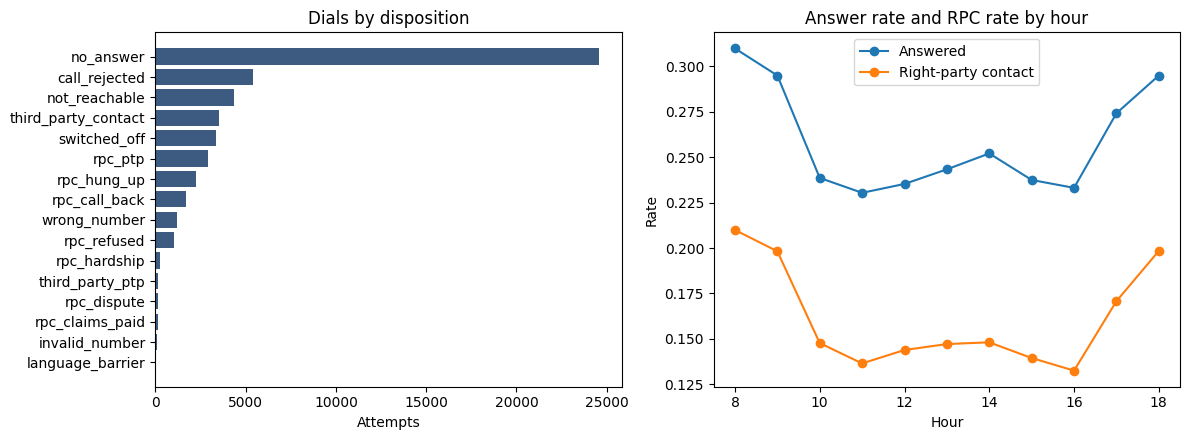

Parsed promise dates range from 2026-04-02 to 2026-07-20
RPC rate overall: 0.164
PTP rate overall: 0.060
Share of PTPs that are third-party: 0.050


In [93]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
disp_counts = dials["disposition"].value_counts()
axes[0].barh(disp_counts.index[::-1], disp_counts.values[::-1], color="#3D5A80")
axes[0].set_title("Dials by disposition")
axes[0].set_xlabel("Attempts")

by_hour = dials.groupby("hour").agg(rpc=("y_rpc", "mean"), answered=("y_answered", "mean"))
axes[1].plot(by_hour.index, by_hour["answered"], marker="o", label="Answered")
axes[1].plot(by_hour.index, by_hour["rpc"], marker="o", label="Right-party contact")
axes[1].set_title("Answer rate and RPC rate by hour")
axes[1].set_xlabel("Hour")
axes[1].set_ylabel("Rate")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG / "dial_outcomes_by_hour.png", dpi=120, bbox_inches="tight")
plt.show()

promise = dials.loc[dials["promise_date"].notna(), "promise_date"]
print("Parsed promise dates range from", promise.min().date(), "to", promise.max().date())
print("RPC rate overall: {:.3f}".format(dials["y_rpc"].mean()))
print("PTP rate overall: {:.3f}".format(dials["y_ptp"].mean()))
print("Share of PTPs that are third-party: {:.3f}".format((dials["ptp_party"] == "third_party").sum() / max(dials["y_ptp"].sum(), 1)))

## 6. Account matrix

One row per account. Counts of phones, dials, PTPs, visits, payments and traces sit next to the static loan fields. Null ability and null salary day stay null; the flags from step 3 say that the value was never observed.

Phones with no dials are counted in `n_phones_never_dialled`. They are not counted as failures.

In [94]:
phone_cov = phones.groupby("account_id").agg(
    n_phones=("phone_id", "size"),
    n_phones_self=("relation_group", lambda s: int((s == "self").sum())),
    n_phones_reference=("relation_group", lambda s: int((s == "reference").sum())),
    n_phones_office=("relation_group", lambda s: int((s == "office").sum())),
)
dialled_cps = set(dials.loc[dials["link_ok"], "cp_id"])
phones["was_dialled"] = phones["cp_id"].isin(dialled_cps)
never = phones.loc[~phones["was_dialled"]].groupby("account_id").size().rename("n_phones_never_dialled")

dial_cov = dials.groupby("account_id").agg(
    n_attempts=("attempt_id", "size"),
    n_answered=("y_answered", "sum"),
    n_rpc=("y_rpc", "sum"),
    n_third_party=("y_third_party", "sum"),
    n_wrong=("y_wrong", "sum"),
    n_invalid_signal=("y_invalid", "sum"),
    n_ptp=("y_ptp", "sum"),
    n_borrower_ptp=("ptp_party", lambda s: int((s == "borrower").sum())),
    n_third_party_ptp=("ptp_party", lambda s: int((s == "third_party").sum())),
    first_ptp_captured=("ptp_captured_date", "min"),
    last_ptp_captured=("ptp_captured_date", "max"),
    n_ptp_with_promise_date=("promise_date", lambda s: int(s.notna().sum())),
    first_attempt=("attempt_ts", "min"),
    last_attempt=("attempt_ts", "max"),
)
addr_cov = addresses.groupby("account_id").size().rename("n_addresses")
visit_cov = visits.groupby("account_id").agg(
    n_visits=("visit_id", "size"),
    n_met_borrower=("outcome", lambda s: int(s.isin(["met_borrower", "cash_collected"]).sum())),
    n_met_family=("outcome", lambda s: int((s == "met_family").sum())),
    n_locked=("outcome", lambda s: int((s == "locked_premises").sum())),
    n_shifted=("outcome", lambda s: int((s == "neighbour_says_shifted").sum())),
    n_visit_ptp=("ptp_id", lambda s: int(s.notna().sum())),
)
pay_cov = payments.groupby("account_id").agg(
    n_payments=("payment_id", "size"),
    amount_paid=("amount", "sum"),
)
trace_cov = traces.groupby("account_id").agg(
    n_traces=("trace_id", "size"),
    n_traces_found=("result", lambda s: int((s != "no_new_info").sum())),
)
verified_cov = verified.groupby("account_id").size().rename("n_verified_phones")

account_matrix = accounts.merge(phone_cov, on="account_id", how="left")
account_matrix = account_matrix.merge(never, on="account_id", how="left")
account_matrix = account_matrix.merge(dial_cov, on="account_id", how="left")
account_matrix = account_matrix.merge(addr_cov, on="account_id", how="left")
account_matrix = account_matrix.merge(visit_cov, on="account_id", how="left")
account_matrix = account_matrix.merge(pay_cov, on="account_id", how="left")
account_matrix = account_matrix.merge(trace_cov, on="account_id", how="left")
account_matrix = account_matrix.merge(verified_cov, on="account_id", how="left")

count_cols = [c for c in account_matrix.columns if c.startswith("n_")] + ["amount_paid"]
account_matrix[count_cols] = account_matrix[count_cols].fillna(0)
for col in ["n_phones", "n_attempts", "n_ptp", "n_visits", "n_payments", "n_traces", "n_verified_phones", "n_phones_never_dialled"]:
    account_matrix[col] = account_matrix[col].astype(int)

assert account_matrix["account_id"].is_unique
assert len(account_matrix) == len(accounts)
account_matrix.to_csv(OUT / "account_matrix.csv", index=False)
print("wrote", OUT / "account_matrix.csv")
print("accounts with no dials:", int((account_matrix["n_attempts"] == 0).sum()))
print("phones never dialled:", int(phones["was_dialled"].eq(False).sum()), "of", len(phones))
display(account_matrix[["n_phones", "n_attempts", "n_rpc", "n_ptp", "n_payments", "amount_paid", "n_traces"]].describe().round(2))

wrote /Users/adityagupta/Documents/OPEN_IIT/OPEN_IIT_PS2/outputs/account_matrix.csv
accounts with no dials: 32
phones never dialled: 1684 of 5719
       n_phones  n_attempts    n_rpc    n_ptp  n_payments  amount_paid  n_traces
count   2400.00     2400.00  2400.00  2400.00     2400.00      2400.00   2400.00
mean       2.38       21.29     3.50     1.29        0.90     11403.73      0.32
std        0.91       11.77     2.86     1.17        0.77     26309.11      0.60
min        1.00        0.00     0.00     0.00        0.00         0.00      0.00
25%        2.00       12.00     1.00     0.00        0.00         0.00      0.00
50%        2.00       22.00     3.00     1.00        1.00      3575.00      0.00
75%        3.00       30.00     5.00     2.00        1.00     11400.00      1.00
max        6.00       57.00    16.00     8.00        6.00    438000.00      3.00


## 7. Point-in-time history on each dial

For attempt *t*, every rate uses only attempts on that same number with timestamp strictly earlier than *t*. The disposition, remark, ring time and talk time of attempt *t* are not features. `selection_propensity` is also left out: it records the old dialer's choice, and a model that uses it learns the old policy rather than the number's health.

Rates on a first attempt are filled later with the **training-set** average, and `no_prior_attempt = 1` tells the model that the fill is not evidence. Filling a first attempt with rate 0 would treat "never called" as "never answers".

In [95]:
model_dials = dials.loc[dials["link_ok"] & ~dials["data_issue"]].sort_values(["cp_id", "attempt_ts"]).copy()
grouped = model_dials.groupby("cp_id", sort=False)
model_dials["prior_n"] = grouped.cumcount()
model_dials["no_prior_attempt"] = (model_dials["prior_n"] == 0).astype(int)
model_dials["prev_ts"] = grouped["attempt_ts"].shift(1)
model_dials["days_since_last_attempt"] = (model_dials["attempt_ts"] - model_dials["prev_ts"]).dt.total_seconds() / 86400
model_dials["days_since_added"] = (model_dials["attempt_ts"].dt.normalize() - model_dials["added_date"]).dt.days
model_dials["days_since_added"] = model_dials["days_since_added"].clip(lower=0)

for src, dest in [
    ("y_answered", "prior_answer_rate"),
    ("y_rpc", "prior_rpc_rate"),
    ("y_third_party", "prior_tp_rate"),
    ("y_wrong", "prior_wrong_rate"),
    ("y_off", "prior_off_rate"),
    ("y_reject", "prior_reject_rate"),
]:
    prior_sum = grouped[src].cumsum() - model_dials[src]
    model_dials[dest] = np.where(model_dials["prior_n"] > 0, prior_sum / model_dials["prior_n"], np.nan)

context_cols = [
    "account_id", "portfolio", "income_type", "bucket_start", "dpd_start", "emi_amount",
    "overdue_start", "outstanding", "bureau_score_band", "other_active_loans",
    "paid_other_lenders_30d", "ability_to_pay_estimate", "ability_missing",
    "prev_ptp_count", "prev_ptp_broken", "split",
]
model_dials = model_dials.drop(columns=["split"], errors="ignore")
model_dials = model_dials.merge(accounts[context_cols], on="account_id", how="left", validate="many_to_one")

NUM_COLS = [
    "prior_n", "prior_answer_rate", "prior_rpc_rate", "prior_tp_rate", "prior_wrong_rate",
    "prior_off_rate", "prior_reject_rate", "days_since_added", "days_since_last_attempt",
    "no_prior_attempt", "priority_slot", "n_accounts_sharing_phone_id", "dpd_start",
    "overdue_start", "outstanding", "emi_amount", "ability_to_pay_estimate", "ability_missing",
    "prev_ptp_count", "prev_ptp_broken", "other_active_loans", "paid_other_lenders_30d",
]
CAT_COLS = [
    "source", "relation_group", "hour_bucket", "portfolio", "income_type",
    "bucket_start", "channel", "bureau_score_band",
]
RATE_COLS = [c for c in NUM_COLS if c.startswith("prior_") and c.endswith("_rate")]
print("modelling dials", len(model_dials), "train", int((model_dials["split"] == "train").sum()))

modelling dials 51081 train 35815


## 8. Beta–Bernoulli with exponential decay

For a contact point, each past dial is a coin-flip that came up right-party contact or not. A dial *d* days old has weight `exp(-λ d)` with λ = 0.05 per day, so a call from about two weeks ago has roughly half the weight of a call today.

```
alpha = alpha0 + sum_i  w_i * y_i
beta  = beta0  + sum_i  w_i * (1 - y_i)
P(RPC) = alpha / (alpha + beta)
```

`alpha0` and `beta0` come from the training RPC rate of the same source and relation, with four pseudo-calls of strength. A bureau reference number therefore does not start from the same prior as a KYC self number. Untested numbers stop at this prior. They are not pushed toward zero.

In [96]:
train_attempts = model_dials.loc[model_dials["split"] == "train"]
global_rate = float(train_attempts["y_rpc"].mean())
by_source = train_attempts.groupby("source")["y_rpc"].agg(["mean", "size"])
by_both = train_attempts.groupby(["source", "relation_group"])["y_rpc"].agg(["mean", "size"])

def lookup_prior(source, relation):
    key = (source, relation)
    if key in by_both.index and by_both.loc[key, "size"] >= 30:
        return float(by_both.loc[key, "mean"])
    if source in by_source.index and by_source.loc[source, "size"] >= 30:
        return float(by_source.loc[source, "mean"])
    return global_rate

phones["source_prior_rate"] = [
    lookup_prior(s, r) for s, r in zip(phones["source"], phones["relation_group"])
]
phones["alpha0"] = phones["source_prior_rate"] * PRIOR_STRENGTH
phones["beta0"] = (1 - phones["source_prior_rate"]) * PRIOR_STRENGTH

prior_on_attempts = phones.set_index("cp_id")[["alpha0", "beta0"]]
model_dials = model_dials.join(prior_on_attempts, on="cp_id")
model_dials = model_dials.sort_values(["cp_id", "attempt_ts"]).reset_index(drop=True)

beta_score = np.empty(len(model_dials))
cp_codes = model_dials["cp_id"].to_numpy()
y_all = model_dials["y_rpc"].to_numpy(dtype=float)
t_all = model_dials["attempt_ts"].to_numpy(dtype="datetime64[ns]")
a0_all = model_dials["alpha0"].to_numpy(dtype=float)
b0_all = model_dials["beta0"].to_numpy(dtype=float)

start = 0
for i in range(1, len(model_dials) + 1):
    boundary = i == len(model_dials) or cp_codes[i] != cp_codes[start]
    if not boundary:
        continue
    y = y_all[start:i]
    t = t_all[start:i]
    a0 = a0_all[start]
    b0 = b0_all[start]
    for k in range(i - start):
        if k == 0:
            beta_score[start + k] = a0 / (a0 + b0)
            continue
        age_days = (t[k] - t[:k]).astype("timedelta64[s]").astype(float) / 86400.0
        w = np.exp(-DECAY_LAMBDA * np.clip(age_days, 0, None))
        alpha = a0 + np.sum(w * y[:k])
        beta = b0 + np.sum(w * (1.0 - y[:k]))
        beta_score[start + k] = alpha / (alpha + beta)
    start = i

model_dials["p_beta_attempt"] = beta_score

# Phone-level posterior as of the end of the window, using every dial before AS_OF.
phone_rows = []
for cp_id, g in model_dials.groupby("cp_id", sort=False):
    a0 = float(g["alpha0"].iloc[0])
    b0 = float(g["beta0"].iloc[0])
    age_days = (AS_OF - g["attempt_ts"]).dt.total_seconds().to_numpy() / 86400.0
    w = np.exp(-DECAY_LAMBDA * np.clip(age_days, 0, None))
    y = g["y_rpc"].to_numpy(dtype=float)
    alpha = a0 + np.sum(w * y)
    beta = b0 + np.sum(w * (1.0 - y))
    total = alpha + beta
    phone_rows.append((cp_id, alpha / total, (alpha * beta) / (total ** 2 * (total + 1)), len(g)))

beta_phone = pd.DataFrame(phone_rows, columns=["cp_id", "p_beta_rpc", "var_beta_rpc", "n_attempts_model"])
# Untested phones keep the prior mean.
missing_cp = phones.loc[~phones["cp_id"].isin(beta_phone["cp_id"]), ["cp_id", "source_prior_rate"]].copy()
missing_cp["p_beta_rpc"] = missing_cp["source_prior_rate"]
missing_cp["var_beta_rpc"] = np.nan
missing_cp["n_attempts_model"] = 0
beta_phone = pd.concat([
    beta_phone,
    missing_cp[["cp_id", "p_beta_rpc", "var_beta_rpc", "n_attempts_model"]],
], ignore_index=True)
phones = phones.merge(beta_phone, on="cp_id", how="left", validate="one_to_one")
print("Beta prior RPC rate, global train: {:.3f}".format(global_rate))
print(phones["p_beta_rpc"].describe().round(3))

Beta prior RPC rate, global train: 0.163
count    5719.000
mean        0.144
std         0.068
min         0.013
25%         0.084
50%         0.150
75%         0.186
max         0.473
Name: p_beta_rpc, dtype: float64


## 9. Logistic probability of RPC on the next attempt

The logistic model is the attempt-level probability: given the history so far and the hour we intend to dial, what is `P(RPC)`.

Training uses train accounts only. Metrics below are validation accounts only. Coefficients are estimated with L2 regularisation so the probabilities stay inside a smooth curve rather than fitting noise in a rare disposition. Class weights are left at the natural frequency. Reweighting would move the probabilities away from the observed RPC rate.

The phone score is the best of the four daytime slots, scored with the full history as of 29 June 2026. A phone with no dials does not get a logistic score. Its dial score stays at the Beta prior.

In [97]:
def classification_scores(y, p, name):
    y = np.asarray(y).astype(int)
    p = np.clip(np.asarray(p).astype(float), 1e-6, 1 - 1e-6)
    out = {"model": name, "n": int(len(y)), "positives": int(y.sum()), "base_rate": float(y.mean())}
    if y.min() != y.max():
        out["auc"] = float(roc_auc_score(y, p))
    else:
        out["auc"] = np.nan
    out["brier"] = float(brier_score_loss(y, p))
    out["log_loss"] = float(log_loss(y, p))
    edges = np.linspace(0, 1, 11)
    ece = 0.0
    for b in range(10):
        right = edges[b + 1]
        mask = (p >= edges[b]) & (p < right if b < 9 else p <= right)
        if mask.sum() == 0:
            continue
        ece += mask.mean() * abs(y[mask].mean() - p[mask].mean())
    out["ece"] = float(ece)
    return out

def design(frame, columns, medians):
    num = frame[NUM_COLS].apply(pd.to_numeric, errors="coerce")
    num = num.fillna(medians)
    cat = pd.get_dummies(frame[CAT_COLS].astype("string").fillna("missing"), dtype=float)
    X = pd.concat([num.reset_index(drop=True), cat.reset_index(drop=True)], axis=1)
    X = X.reindex(columns=columns, fill_value=0.0)
    return X

train_df = model_dials.loc[model_dials["split"] == "train"].copy()
val_df = model_dials.loc[model_dials["split"] == "validation"].copy()

rate_fill = train_df.loc[train_df["prior_n"] > 0, RATE_COLS].mean()
ability_fill = train_df["ability_to_pay_estimate"].median()
medians = train_df[NUM_COLS].apply(pd.to_numeric, errors="coerce").median()
medians[RATE_COLS] = rate_fill.values
medians["ability_to_pay_estimate"] = ability_fill
medians = medians.fillna(0.0)

for frame in (train_df, val_df, model_dials):
    frame[RATE_COLS] = frame[RATE_COLS].fillna(rate_fill)
    frame["days_since_last_attempt"] = frame["days_since_last_attempt"].fillna(0.0)

y_train = train_df["y_rpc"].to_numpy(dtype=int)
base_design = pd.get_dummies(train_df[CAT_COLS].astype("string").fillna("missing"), dtype=float)
num_train = train_df[NUM_COLS].apply(pd.to_numeric, errors="coerce").fillna(medians)
X_train_raw = pd.concat([num_train.reset_index(drop=True), base_design.reset_index(drop=True)], axis=1)
keep_cols = X_train_raw.columns[X_train_raw.nunique() > 1]
X_train_raw = X_train_raw[keep_cols]

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
logit = LogisticRegression(C=1.0, max_iter=1000, solver="lbfgs", random_state=SEED)
logit.fit(X_train, y_train)

def predict_rpc(frame):
    X = design(frame, keep_cols, medians)
    Xs = scaler.transform(X)
    return logit.predict_proba(Xs)[:, 1]

train_df["p_logit"] = predict_rpc(train_df)
val_df["p_logit"] = predict_rpc(val_df)
val_base = np.full(len(val_df), y_train.mean())
metric_rows = [
    classification_scores(val_df["y_rpc"], val_base, "constant train RPC rate"),
    classification_scores(val_df["y_rpc"], val_df["p_beta_attempt"], "beta decay, history before the attempt"),
    classification_scores(val_df["y_rpc"], val_df["p_logit"], "logistic, history before the attempt"),
]
metrics = pd.DataFrame(metric_rows)
display(metrics.round(4))

# Score each tested phone at each daytime slot, using the full history as of AS_OF.
hist = model_dials.groupby("cp_id").agg(
    prior_n=("y_rpc", "size"),
    prior_answer_rate=("y_answered", "mean"),
    prior_rpc_rate=("y_rpc", "mean"),
    prior_tp_rate=("y_third_party", "mean"),
    prior_wrong_rate=("y_wrong", "mean"),
    prior_off_rate=("y_off", "mean"),
    prior_reject_rate=("y_reject", "mean"),
    last_ts=("attempt_ts", "max"),
)
static = phones.merge(accounts[context_cols], on="account_id", how="left", suffixes=("", "_acct"))
snap = static.merge(hist, on="cp_id", how="left")
snap["no_prior_attempt"] = snap["prior_n"].fillna(0).eq(0).astype(int)
snap["prior_n"] = snap["prior_n"].fillna(0)
snap["days_since_added"] = (AS_OF.normalize() - snap["added_date"]).dt.days.clip(lower=0)
snap["days_since_last_attempt"] = (AS_OF - snap["last_ts"]).dt.total_seconds() / 86400
snap["channel"] = "tele_agent"
snap[RATE_COLS] = snap[RATE_COLS].fillna(rate_fill)
snap["days_since_last_attempt"] = snap["days_since_last_attempt"].fillna(0.0)

tested = snap["prior_n"] > 0
slot_frames = []
for slot in ["08-10", "10-12", "12-14", "14-19"]:
    part = snap.loc[tested].copy()
    part["hour_bucket"] = slot
    part["p_slot"] = predict_rpc(part)
    part["slot"] = slot
    slot_frames.append(part[["cp_id", "slot", "p_slot"]])
slot_scores = pd.concat(slot_frames, ignore_index=True)
best_slot = slot_scores.sort_values("p_slot", ascending=False).groupby("cp_id", as_index=False).head(1)
best_slot = best_slot.rename(columns={"slot": "best_hour_bucket", "p_slot": "p_logit_rpc"})
phones = phones.merge(best_slot, on="cp_id", how="left", validate="one_to_one")
phones["p_rpc_score"] = np.where(phones["p_logit_rpc"].notna(), phones["p_logit_rpc"], phones["p_beta_rpc"])
phones["score_source"] = np.where(phones["p_logit_rpc"].notna(), "logistic_next_attempt", "beta_prior_untested")
print(phones["score_source"].value_counts().to_string())

                                    model     n  positives  base_rate     auc   brier  log_loss     ece
0                 constant train RPC rate  7859       1218      0.155  0.5000  0.1310    0.4315  0.0084
1  beta decay, history before the attempt  7859       1218      0.155  0.6635  0.1260    0.4105  0.0066
2    logistic, history before the attempt  7859       1218      0.155  0.6827  0.1243    0.4032  0.0075
score_source
logistic_next_attempt    4035
beta_prior_untested      1684


## 10. Probability the account pays if we reach the borrower

The label is: among right-party contacts whose 14-day follow-up window is fully inside the data (call on or before 15 June 2026), did any payment land in `(call time, call time + 14 days]`?

This label mixes contact-driven payments and self-cure (NACH, branch cash). It answers "did money arrive after we reached them?", which is the recovery term we can estimate with this file. It is not a live fake-PTP detector. That is a different problem, and the call transcript it needs is not in the PS2 files.

Features are the account attributes stored on the loan: delinquency, ability to pay, past promises, portfolio. Counts of calls inside this window are not used, because those calls are the events that define the label.

Accounts whose only right-party contacts fall in the last 14 days are left unlabelled (`y_repay` null) and are still scored.

In [98]:
pay_times = {
    aid: g["payment_ts"].sort_values().to_numpy(dtype="datetime64[ns]")
    for aid, g in payments.groupby("account_id")
}

def paid_within(account_id, start, end):
    arr = pay_times.get(account_id)
    if arr is None or len(arr) == 0:
        return False
    i = np.searchsorted(arr, np.datetime64(start), side="right")
    j = np.searchsorted(arr, np.datetime64(end), side="right")
    return j > i

rpc_calls = model_dials.loc[model_dials["y_rpc"].eq(1), ["account_id", "attempt_ts", "split"]].copy()
rpc_calls["mature"] = rpc_calls["attempt_ts"] <= (AS_OF - pd.Timedelta(days=14))
mature_rpc = rpc_calls.loc[rpc_calls["mature"]].copy()
mature_rpc["paid_14"] = [
    paid_within(aid, ts, ts + pd.Timedelta(days=14))
    for aid, ts in zip(mature_rpc["account_id"], mature_rpc["attempt_ts"])
]
repay_label = mature_rpc.groupby("account_id", as_index=False).agg(
    y_repay=("paid_14", "max"),
    n_mature_rpc=("paid_14", "size"),
)
repay_label["y_repay"] = repay_label["y_repay"].astype(int)

REPAY_NUM = [
    "dpd_start", "emi_amount", "overdue_start", "outstanding", "ability_to_pay_estimate",
    "ability_missing", "prev_ptp_count", "prev_ptp_broken", "other_active_loans",
    "paid_other_lenders_30d", "has_salary_day",
]
REPAY_CAT = [
    "portfolio", "income_type", "bucket_start", "bureau_score_band", "town_id",
    "last_bounce_reason", "preferred_language",
]
repay = accounts.merge(repay_label, on="account_id", how="left")
train_repay = repay.loc[(repay["split"] == "train") & repay["y_repay"].notna()].copy()
val_repay = repay.loc[(repay["split"] == "validation") & repay["y_repay"].notna()].copy()
repay_medians = train_repay[REPAY_NUM].apply(pd.to_numeric, errors="coerce").median().fillna(0.0)

def repay_design(frame, columns=None):
    num = frame[REPAY_NUM].apply(pd.to_numeric, errors="coerce").fillna(repay_medians)
    cat = pd.get_dummies(frame[REPAY_CAT].astype("string").fillna("missing"), dtype=float)
    X = pd.concat([num.reset_index(drop=True), cat.reset_index(drop=True)], axis=1)
    if columns is not None:
        X = X.reindex(columns=columns, fill_value=0.0)
    return X

X_repay_train = repay_design(train_repay)
repay_cols = X_repay_train.columns[X_repay_train.nunique() > 1]
X_repay_train = X_repay_train[repay_cols]
repay_scaler = StandardScaler()
Xtr = repay_scaler.fit_transform(X_repay_train)
repay_model = LogisticRegression(C=1.0, max_iter=1000, solver="lbfgs", random_state=SEED)
repay_model.fit(Xtr, train_repay["y_repay"].to_numpy(dtype=int))

def predict_repay(frame):
    X = repay_design(frame, repay_cols)
    return repay_model.predict_proba(repay_scaler.transform(X))[:, 1]

val_repay = val_repay.copy()
val_repay["p_repay_if_reached"] = predict_repay(val_repay)
repay_base = np.full(len(val_repay), train_repay["y_repay"].mean())
repay_metrics = pd.DataFrame([
    classification_scores(val_repay["y_repay"], repay_base, "constant train keep rate"),
    classification_scores(val_repay["y_repay"], val_repay["p_repay_if_reached"], "logistic P(pay within 14d | RPC)"),
])
display(repay_metrics.round(4))
print("Train accounts with a mature RPC:", len(train_repay), "keep rate {:.3f}".format(train_repay["y_repay"].mean()))

repay["p_repay_if_reached"] = predict_repay(repay)
account_matrix = account_matrix.merge(
    repay[["account_id", "y_repay", "n_mature_rpc", "p_repay_if_reached"]],
    on="account_id",
    how="left",
    validate="one_to_one",
)

                              model    n  positives  base_rate    auc   brier  log_loss     ece
0          constant train keep rate  305        141     0.4623  0.500  0.2498    0.6926  0.0342
1  logistic P(pay within 14d | RPC)  305        141     0.4623  0.604  0.2428    0.6782  0.0529
Train accounts with a mature RPC: 1446 keep rate 0.497


## 11. Observable Markov chain

Before hiding the state, look at the chain we can actually see. Each symbol is the outcome of one dial. The matrix is `P(next outcome | this outcome)`, estimated on **train accounts only**.

Persistence on the diagonal (a switched-off call followed by another switched-off call) is why a static classifier under-reacts: the health of the number moves, and it also stays stuck. The hidden model in the next step is built to track that.

obs_next          rpc  third_party  wrong_number  rejected  no_answer  switched_off  not_reachable  does_not_exist  answered_other
obs                                                                                                                               
rpc             0.245        0.037         0.005     0.073      0.576         0.005          0.059           0.000           0.001
third_party     0.087        0.322         0.039     0.034      0.437         0.000          0.079           0.000           0.000
wrong_number    0.059        0.116         0.161     0.129      0.454         0.000          0.081           0.000           0.000
rejected        0.108        0.027         0.023     0.259      0.507         0.005          0.072           0.000           0.000
no_answer       0.195        0.064         0.023     0.108      0.542         0.005          0.061           0.000           0.001
switched_off    0.008        0.001         0.003     0.005      0.028         0.734

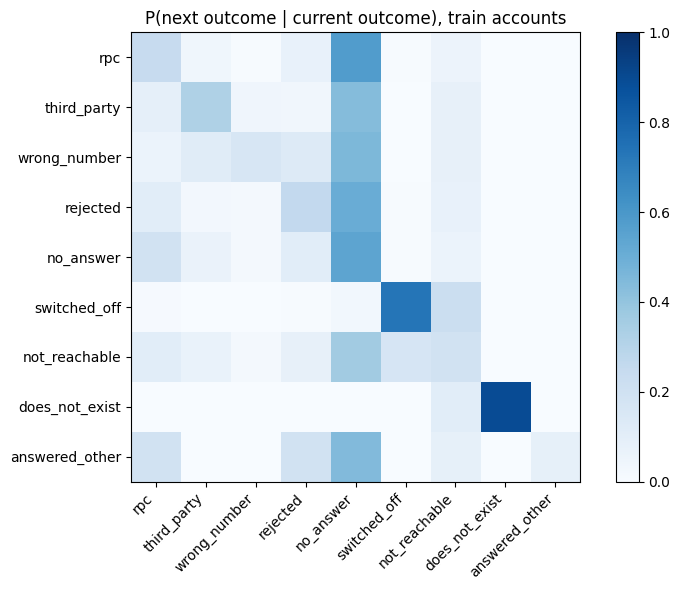

In [99]:
chain = model_dials.loc[model_dials["split"] == "train", ["cp_id", "attempt_ts", "obs"]].sort_values(["cp_id", "attempt_ts"])
chain["obs_next"] = chain.groupby("cp_id")["obs"].shift(-1)
pairs = chain.dropna(subset=["obs_next"])
transition = pd.crosstab(pairs["obs"], pairs["obs_next"], normalize="index").reindex(index=OBS_ORDER, columns=OBS_ORDER)
display(transition.round(3))
transition.to_csv(OUT / "observable_markov.csv")

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(transition.fillna(0).to_numpy(), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(OBS_ORDER)))
ax.set_yticks(range(len(OBS_ORDER)))
ax.set_xticklabels(OBS_ORDER, rotation=45, ha="right")
ax.set_yticklabels(OBS_ORDER)
ax.set_title("P(next outcome | current outcome), train accounts")
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(FIG / "observable_markov.png", dpi=120, bbox_inches="tight")
plt.show()

## 12. Hidden Markov model

The hidden state is the health of the phone, not the last disposition. Dispositions are noisy: an agent can log a right-party hang-up, a relative can answer, a switched-off spell can be temporary.

States: `valid_reachable`, `valid_avoiding`, `temp_unreachable`, `off_long_term`, `third_party`, `recycled_or_wrong`, `invalid`.

**Transitions.** A rate matrix `Q` (rows sum to 0) says how fast a phone drifts per day. The transition matrix across a gap of `dt` days is `expm(Q * dt)`. Two calls on the same morning barely move the state. A silent month does. `invalid` is absorbing. `recycled_or_wrong` and `third_party` almost are: once the number is someone else's, time does not give it back. A single noisy "wrong number" can still be outweighed by later right-party calls, because the update is Bayesian rather than a hard flip.

**Emissions.** Hand-set pseudocounts encode the domain story (a reachable borrower generates `rpc`; a dead number generates `does_not_exist`; a reference number generates `third_party`). Those counts are then added to the outcomes of **train** phones whose weak label is not `unknown`. Validation and test phones do not contribute to `B`. Gold labels do not contribute at all.

**Weak labels** are rules on the call history (invalid network response, RPC then later wrong-number, third-party share of answers, long switched-off run, human rejection without RPC). They initialise the emission matrix. They are not the model output.

**Filter.** Start from a prior that depends on source and relation. For each call, move the belief across the time gap, multiply by the emission of the outcome, and normalise. The last belief is the state distribution as of the last call, decayed from the added-date up to that call.

`P(reachable)` used downstream is the posterior on `valid_reachable`. `P(this is the borrower's number)` is `valid_reachable + valid_avoiding`. Those are different: an avoiding borrower still owns the number, and the right action is a channel switch, not a skip-trace.

In [100]:
STATES = [
    "valid_reachable", "valid_avoiding", "temp_unreachable", "off_long_term",
    "third_party", "recycled_or_wrong", "invalid",
]
# Daily rates from row-state to column-state. Diagonal is set so each row sums to 0.
RATE_TO = {
    0: {1: 0.004, 2: 0.003, 3: 0.0015, 5: 0.0008},
    1: {0: 0.003, 2: 0.004, 3: 0.002},
    2: {0: 0.005, 1: 0.003, 3: 0.008},
    3: {2: 0.002, 5: 0.004, 6: 0.001},
    4: {5: 0.001},
    5: {4: 0.0005},
    6: {},
}
Q = np.zeros((len(STATES), len(STATES)))
for i, dest in RATE_TO.items():
    for j, rate in dest.items():
        Q[i, j] += rate
    Q[i, i] = -Q[i].sum()

PSEUDO = pd.DataFrame(
    [
        [40, 2, 1, 8, 20, 3, 4, 0.2, 3],
        [4, 2, 1, 25, 30, 4, 6, 0.2, 2],
        [2, 1, 1, 6, 20, 8, 25, 0.3, 1],
        [1, 1, 2, 3, 8, 40, 20, 0.5, 0.5],
        [2, 40, 4, 6, 15, 3, 3, 0.2, 5],
        [1, 4, 40, 4, 12, 5, 5, 2, 2],
        [0.2, 0.5, 3, 1, 4, 3, 3, 40, 0.3],
    ],
    index=STATES,
    columns=OBS_ORDER,
    dtype=float,
)

def assign_weak(g):
    g = g.sort_values("attempt_ts")
    if len(g) == 0:
        return "unknown"
    if g["network_response"].eq("number_does_not_exist").any() or g["disposition"].eq("invalid_number").any():
        return "invalid"
    rpc_times = g.loc[g["y_rpc"].eq(1), "attempt_ts"]
    wrong_times = g.loc[g["disposition"].eq("wrong_number"), "attempt_ts"]
    if len(rpc_times) >= 1 and len(wrong_times) >= 2 and wrong_times.max() > rpc_times.min():
        return "recycled_or_wrong"
    answered = g.loc[g["y_answered"].eq(1)]
    rpc_share = float(answered["y_rpc"].mean()) if len(answered) else 0.0
    tp_share = float(answered["y_third_party"].mean()) if len(answered) else 0.0
    if len(answered) >= 1 and tp_share >= 0.5 and rpc_share < 0.3:
        return "third_party"
    if len(rpc_times) >= 1 and rpc_share >= 0.5:
        return "valid_reachable"
    last = g["attempt_ts"].max()
    recent = g.loc[g["attempt_ts"] >= last - pd.Timedelta(days=30)]
    if len(g) >= 3 and float(g["y_off"].mean()) >= 0.7 and int(recent["y_answered"].sum()) == 0:
        return "off_long_term"
    if len(g) < 3:
        return "unknown"
    if len(rpc_times) == 0 and float(g["y_human"].mean()) >= 0.3:
        return "valid_avoiding"
    return "temp_unreachable"

weak_rows = [(cp_id, assign_weak(g)) for cp_id, g in model_dials.groupby("cp_id", sort=False)]
weak = pd.DataFrame(weak_rows, columns=["cp_id", "weak_state"])
phones = phones.merge(weak, on="cp_id", how="left", validate="one_to_one")
phones["weak_state"] = phones["weak_state"].fillna("unknown")

train_cp = set(phones.loc[phones["split"] == "train", "cp_id"])
labelled = model_dials.merge(weak, on="cp_id", how="inner")
labelled = labelled.loc[labelled["cp_id"].isin(train_cp) & labelled["weak_state"].ne("unknown")]
observed_counts = pd.crosstab(labelled["weak_state"], labelled["obs"]).reindex(index=STATES, columns=OBS_ORDER).fillna(0.0)
B_df = PSEUDO.add(observed_counts, fill_value=0.0)
B_df = B_df.div(B_df.sum(axis=1), axis=0)
B = B_df.to_numpy(dtype=float)
obs_index = {name: i for i, name in enumerate(OBS_ORDER)}

A_CACHE = {}

def transition(dt_days):
    key = round(max(dt_days, 0.0), 2)
    if key not in A_CACHE:
        A_CACHE[key] = expm(Q * key)
    return A_CACHE[key]

def initial_pi(relation, source):
    if relation == "self" and source in {"kyc_origination", "borrower_update"}:
        pi = np.array([0.50, 0.18, 0.12, 0.05, 0.05, 0.06, 0.04])
    elif relation == "reference":
        pi = np.array([0.08, 0.07, 0.10, 0.05, 0.55, 0.10, 0.05])
    elif relation == "office":
        pi = np.array([0.10, 0.08, 0.12, 0.05, 0.45, 0.12, 0.08])
    elif source == "skip_trace":
        pi = np.array([0.28, 0.12, 0.18, 0.08, 0.12, 0.14, 0.08])
    else:
        pi = np.array([0.25, 0.15, 0.20, 0.10, 0.15, 0.10, 0.05])
    return pi / pi.sum()

def forward_filter(times, obs_names, pi, t0):
    alpha = pi.astype(float).copy()
    t_prev = t0
    for ts, name in zip(times, obs_names):
        dt = (ts - t_prev).total_seconds() / 86400.0
        pred = alpha @ transition(dt)
        alpha = pred * B[:, obs_index[name]]
        total = alpha.sum()
        if not np.isfinite(total) or total <= 0:
            alpha = pred
            total = alpha.sum()
        alpha = alpha / total
        t_prev = ts
    return alpha

attempt_groups = {cp_id: g.sort_values("attempt_ts") for cp_id, g in model_dials.groupby("cp_id", sort=False)}
posterior_rows = []
for rec in phones.itertuples(index=False):
    pi = initial_pi(rec.relation_group, rec.source)
    t0 = rec.added_date if pd.notna(rec.added_date) else AS_OF
    g = attempt_groups.get(rec.cp_id)
    if g is None or len(g) == 0:
        alpha = pi
    else:
        if pd.isna(t0):
            t0 = g["attempt_ts"].iloc[0]
        alpha = forward_filter(g["attempt_ts"], g["obs"], pi, pd.Timestamp(t0))
    posterior_rows.append((rec.cp_id, *alpha, STATES[int(np.argmax(alpha))]))

post_cols = ["cp_id"] + [f"p_state_{s}" for s in STATES] + ["hmm_state"]
posteriors = pd.DataFrame(posterior_rows, columns=post_cols)
phones = phones.drop(columns=[c for c in post_cols if c != "cp_id" and c in phones.columns], errors="ignore")
phones = phones.merge(posteriors, on="cp_id", how="left", validate="one_to_one")
state_cols = [f"p_state_{s}" for s in STATES]
row_sums = phones[state_cols].sum(axis=1)
assert np.allclose(row_sums, 1.0, atol=1e-6)
phones["p_borrower_number"] = phones["p_state_valid_reachable"] + phones["p_state_valid_avoiding"]
phones["p_suppress"] = phones["p_state_third_party"] + phones["p_state_recycled_or_wrong"]
phones["suppress_flag"] = (
    (phones["p_suppress"] >= SUPPRESS_TAU)
    | phones["hmm_state"].isin(["third_party", "recycled_or_wrong", "invalid"])
).astype(int)
print("HMM state counts")
print(phones["hmm_state"].value_counts().to_string())
print("suppressed phones", int(phones["suppress_flag"].sum()))

HMM state counts
hmm_state
valid_reachable      2764
third_party          1659
valid_avoiding        613
off_long_term         370
recycled_or_wrong     197
temp_unreachable       72
invalid                44
suppressed phones 1908


## 13. Check the HMM against the 250 verified numbers

The verification campaign labelled 250 phones on 2 July 2026. Metrics here use the **validation** slice only. The test slice is not scored in this cell.

`borrower_number` is compared with `P(valid_reachable) + P(valid_avoiding)`. Third-party, not-the-borrower, and invalid numbers are the disclosure-risk class. Recall of that class at the placeholder threshold 0.50 is reported with the count, because 40-odd validation phones cannot support a 99% recall claim. The operating threshold will be set for high recall once the sample, or a later gold set, can carry it.

validation gold phones 41
coarse agreement, HMM vs gold: 0.878
coarse agreement, weak rules vs gold: 0.683
                                     model   n  positives  base_rate     auc   brier  log_loss     ece
0             beta P(RPC) vs gold borrower  41         23      0.561  0.9360  0.3877    1.0406  0.4280
1  HMM P(borrower number) vs gold borrower  41         23      0.561  0.9722  0.0636    0.2272  0.0849
2  HMM P(valid_reachable) vs gold borrower  41         23      0.561  0.9094  0.1952    0.6936  0.2325
disclosure-risk recall at tau=0.50: 0.938 on 16 risky validation phones
share of non-risky validation phones suppressed: 0.080 on 25
                     p_borrower_number  p_suppress  p_state_valid_reachable  p_state_off_long_term
verified_status                                                                                   
borrower_number                  0.827       0.106                    0.551                  0.005
not_borrower_number              0.201       0.612 

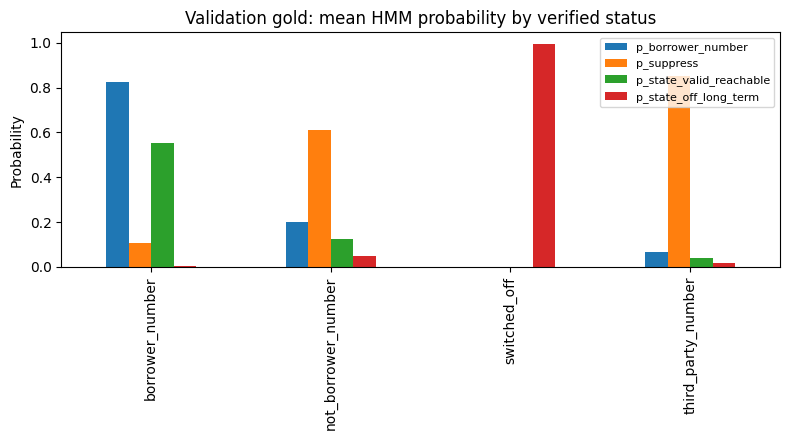

In [101]:
GOLD_COARSE = {
    "borrower_number": "borrower",
    "third_party_number": "third_party",
    "not_borrower_number": "recycled_or_wrong",
    "switched_off": "off_long_term",
    "invalid_number": "invalid",
}
HMM_COARSE = {
    "valid_reachable": "borrower",
    "valid_avoiding": "borrower",
    "temp_unreachable": "temp_unreachable",
    "off_long_term": "off_long_term",
    "third_party": "third_party",
    "recycled_or_wrong": "recycled_or_wrong",
    "invalid": "invalid",
}
gold = verified.merge(
    phones[["cp_id", "account_id", "phone_id", "split", "p_beta_rpc", "p_rpc_score", "p_borrower_number", "p_suppress", "hmm_state", "weak_state"] + state_cols],
    on=["account_id", "phone_id"],
    how="left",
    validate="one_to_one",
)
gold["gold_coarse"] = gold["verified_status"].map(GOLD_COARSE)
gold["hmm_coarse"] = gold["hmm_state"].map(HMM_COARSE)
val_gold = gold.loc[gold["split"] == "validation"].copy()
print("validation gold phones", len(val_gold))
print("coarse agreement, HMM vs gold: {:.3f}".format((val_gold["gold_coarse"] == val_gold["hmm_coarse"]).mean()))
print("coarse agreement, weak rules vs gold: {:.3f}".format((val_gold["gold_coarse"] == val_gold["weak_state"].map(HMM_COARSE).fillna(val_gold["weak_state"])).mean()))

y_borrower = val_gold["verified_status"].eq("borrower_number").astype(int)
gold_metrics = pd.DataFrame([
    classification_scores(y_borrower, val_gold["p_beta_rpc"], "beta P(RPC) vs gold borrower"),
    classification_scores(y_borrower, val_gold["p_borrower_number"], "HMM P(borrower number) vs gold borrower"),
    classification_scores(y_borrower, val_gold["p_state_valid_reachable"], "HMM P(valid_reachable) vs gold borrower"),
])
display(gold_metrics.round(4))

y_risk = val_gold["verified_status"].isin(["third_party_number", "not_borrower_number", "invalid_number"])
flag = val_gold["p_suppress"] >= SUPPRESS_TAU
risk_n = int(y_risk.sum())
safe_n = int((~y_risk).sum())
recall = float((flag & y_risk).sum() / risk_n) if risk_n else np.nan
false_suppress = float((flag & ~y_risk).sum() / safe_n) if safe_n else np.nan
print(f"disclosure-risk recall at tau={SUPPRESS_TAU:.2f}: {recall:.3f} on {risk_n} risky validation phones")
print(f"share of non-risky validation phones suppressed: {false_suppress:.3f} on {safe_n}")

mean_by_gold = val_gold.groupby("verified_status")[["p_borrower_number", "p_suppress", "p_state_valid_reachable", "p_state_off_long_term"]].mean()
display(mean_by_gold.round(3))
fig, ax = plt.subplots(figsize=(8, 4.5))
mean_by_gold.plot(kind="bar", ax=ax)
ax.set_title("Validation gold: mean HMM probability by verified status")
ax.set_ylabel("Probability")
ax.set_xlabel("")
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "hmm_by_verified_status.png", dpi=120, bbox_inches="tight")
plt.show()

## 14. Roll the phone probabilities up to the account

The dial score on a phone is the logistic probability when the number has been tried, and the Beta prior when it has not.

Suppressed phones (third party, recycled, or invalid) are removed before the account roll-up. The debt is not discussed on those numbers.

- `p_best_phone_rpc`: best remaining number.
- `p_any_phone_rpc`: `1 - product(1 - p_i)` over remaining numbers. This is the probability that at least one remaining number produces a right-party contact, if the numbers were independent. Shared household numbers violate that, so treat it as an upper-leaning summary.
- `p_reachable_and_repay`: `p_best_phone_rpc * p_repay_if_reached`.

The action is a first rule table on these probabilities. The cutoffs are placeholders, written in the function, and will be tuned on validation later. Compliance sits in front: if every number is suppressed, the action is `suppress`, not a dial.

In [102]:
def noisy_or(values):
    arr = np.clip(np.asarray(list(values), dtype=float), 0.0, 1.0)
    if len(arr) == 0:
        return 0.0
    return float(1.0 - np.prod(1.0 - arr))

rankable = phones.copy()
rankable.loc[rankable["suppress_flag"].eq(1), "p_rpc_score"] = np.nan
rankable["model_dial_rank"] = rankable.groupby("account_id")["p_rpc_score"].rank(ascending=False, method="first")
phones = phones.drop(columns=["model_dial_rank"], errors="ignore").merge(
    rankable[["cp_id", "model_dial_rank"]], on="cp_id", how="left", validate="one_to_one"
)

usable = phones.loc[phones["suppress_flag"].eq(0)]
best = (
    usable.sort_values("p_rpc_score", ascending=False)
    .groupby("account_id", as_index=False)
    .head(1)[["account_id", "cp_id", "phone_id", "p_rpc_score", "best_hour_bucket", "hmm_state",
              "p_state_valid_reachable", "p_state_valid_avoiding", "p_state_temp_unreachable",
              "p_state_off_long_term", "p_state_invalid"]]
    .rename(columns={
        "cp_id": "best_cp_id",
        "phone_id": "best_phone_id",
        "p_rpc_score": "p_best_phone_rpc",
        "best_hour_bucket": "best_phone_hour",
        "hmm_state": "best_phone_state",
        "p_state_valid_reachable": "p_best_reachable",
        "p_state_valid_avoiding": "p_best_avoiding",
        "p_state_temp_unreachable": "p_best_temp",
        "p_state_off_long_term": "p_best_off",
        "p_state_invalid": "p_best_invalid",
    })
)
any_rpc = usable.groupby("account_id")["p_rpc_score"].apply(noisy_or).rename("p_any_phone_rpc")
n_suppressed = phones.groupby("account_id")["suppress_flag"].sum().rename("n_phones_suppressed")
n_open = usable.groupby("account_id").size().rename("n_phones_dialable")

account_matrix = account_matrix.merge(best, on="account_id", how="left")
account_matrix = account_matrix.merge(any_rpc, on="account_id", how="left")
account_matrix = account_matrix.merge(n_suppressed, on="account_id", how="left")
account_matrix = account_matrix.merge(n_open, on="account_id", how="left")
account_matrix["n_phones_suppressed"] = account_matrix["n_phones_suppressed"].fillna(0).astype(int)
account_matrix["n_phones_dialable"] = account_matrix["n_phones_dialable"].fillna(0).astype(int)
account_matrix["p_any_phone_rpc"] = account_matrix["p_any_phone_rpc"].fillna(0.0)
account_matrix["p_reachable_and_repay"] = account_matrix["p_best_phone_rpc"] * account_matrix["p_repay_if_reached"]

def recommend(row):
    if row.n_phones == 0 or row.n_phones_dialable == 0:
        if row.n_phones_suppressed > 0 and row.n_phones_dialable == 0:
            return "suppress", "every number on file is third-party, recycled, or invalid"
        return "skip_trace", "no dialable phone on file"
    if row.p_best_avoiding >= 0.45 and row.p_best_phone_rpc < 0.25:
        return "switch_channel", "best live number looks like avoidance, not a dead line"
    if row.p_best_phone_rpc >= 0.30:
        return "continue", "best number still has a material chance of right-party contact"
    if row.p_best_off >= 0.40 or row.p_best_invalid >= 0.40:
        return "skip_trace", "remaining numbers look switched off or invalid"
    if row.p_best_temp >= 0.40:
        return "retry_later", "best number looks temporarily unreachable"
    return "switch_contact", "no remaining number is strong enough to keep dialling first"

actions = account_matrix.apply(recommend, axis=1, result_type="expand")
account_matrix["action"] = actions[0]
account_matrix["action_reason"] = actions[1]

cp_out_cols = [
    "cp_id", "account_id", "phone_id", "split", "source", "relation_recorded", "relation_group",
    "added_date", "priority_slot", "n_accounts_sharing_phone_id", "was_dialled", "source_prior_rate",
    "p_beta_rpc", "var_beta_rpc", "p_logit_rpc", "p_rpc_score", "score_source", "best_hour_bucket",
    "model_dial_rank", "weak_state", "hmm_state", "p_borrower_number", "p_suppress", "suppress_flag",
] + state_cols
phones[cp_out_cols].to_csv(OUT / "contact_point_scores.csv", index=False)
account_matrix.to_csv(OUT / "account_probability_matrix.csv", index=False)

print("actions")
print(account_matrix["action"].value_counts().to_string())
summary = account_matrix[["p_best_phone_rpc", "p_any_phone_rpc", "p_repay_if_reached", "p_reachable_and_repay"]].describe().round(3)
display(summary)
print("wrote", OUT / "contact_point_scores.csv")
print("wrote", OUT / "account_probability_matrix.csv")

actions
action
continue          988
switch_contact    888
switch_channel    282
skip_trace        128
suppress           84
retry_later        30
       p_best_phone_rpc  p_any_phone_rpc  p_repay_if_reached  p_reachable_and_repay
count          2316.000         2400.000            2400.000               2316.000
mean              0.282            0.332               0.501                  0.144
std               0.110            0.154               0.129                  0.075
min               0.021            0.000               0.215                  0.006
25%               0.206            0.224               0.396                  0.092
50%               0.282            0.335               0.501                  0.132
75%               0.351            0.449               0.596                  0.188
max               0.619            0.791               0.853                  0.496
wrote /Users/adityagupta/Documents/OPEN_IIT/OPEN_IIT_PS2/outputs/contact_point_scores.csv
wrote /

## 15. How to read the output

`outputs/dial_attempts_with_ptp.csv` — one row per dial. Remark text, PTP id, the date the promise was captured, and the promised date parsed from the remark when one was written.

`outputs/account_matrix.csv` — one row per account, facts only, before model scores.

`outputs/account_probability_matrix.csv` — the same account row plus `p_best_phone_rpc`, `p_any_phone_rpc`, `p_repay_if_reached`, `p_reachable_and_repay`, the best phone, and a first action.

`outputs/contact_point_scores.csv` — one row per phone. This is the grain the problem asks for. The account file is a roll-up of this one.

## What is deliberately not claimed yet

- The logistic and Beta models are compared on the validation dials. The HMM is a filter with a specified rate matrix and a train-only emission count, not a Baum–Welch fit. If the gold table disagrees with it, the next move is to re-estimate emissions and rates on train phones, not to lower the threshold until the small gold set looks good.
`outputs/account_ps2_decisions.csv` is the decision file: one row per account, the problem-statement category, the probability, the threshold it cleared, and the response.

`outputs/contact_point_ps2_categories.csv` is the same assignment on every phone and address. `outputs/ps2_state_thresholds.csv` is the threshold table.

`outputs/account_probability_matrix.csv` still holds the underlying scores. The category file is the one that follows the problem-statement table. An invalid number is sent to trace, not to the disclosure suppress list. Recycled and third-party numbers are suppressed even when the account is dialled on a different number.

## 16. Decision table from the problem statement

The [problem statement](https://docs.google.com/document/d/1NxL-UKH-5oBiEETSASgFiJzYvcrAOrno/edit) assigns each contact point a state, and each state a response. An account takes the response of the contact point we should act on. A state is assigned only when its probability clears that state's threshold. A weak argmax is left as insufficient evidence, and an untested number is not labelled invalid.

Compliance sits in front of dialling. If `recycled` or `third_party` clears its threshold, that number is suppressed and the debt is not discussed on it. `invalid` is not a disclosure suppress: the response is to trace. `valid_avoiding` switches channel. It is not sent to skip-trace.

Skip-trace is not the 15-failed-attempt rule. A trace response is kept only when expected recovery exceeds trace cost:

`EVT = P(find) × P(pay | reached) × outstanding − C_trace`

`P(find)` is the training-set hit rate of past traces. `P(pay | reached)` is the repayment model. `C_trace` is the training-set median trace cost.

| Contact point | State | Threshold | Response |
|---|---|---:|---|
| Phone | Valid and reachable | 0.40 | Keep dialling, at the best time slot |
| Phone | Valid, but borrower avoiding | 0.40 | Switch channel (WhatsApp, field) instead of redialling |
| Phone | Temporarily unreachable | 0.45 | Retry later, with backoff |
| Phone | Switched off long-term | 0.50 | Move to another number, or trace |
| Phone | Recycled to a new subscriber | 0.80 | Stop at once; there is a risk of disclosing the debt to a stranger |
| Phone | Third party (relative, employer, reference) | 0.45 | Use only within Fair Practices Code rules, never discuss the debt |
| Phone | Invalid from the start | 0.50 | Trace |
| Address | Valid and occupied | 0.40 | Visit |
| Address | Valid, but borrower usually absent | 0.40 | Change the visit time |
| Address | Borrower has moved | 0.40 | Trace the new address |
| Address | Hard to find on the ground | 0.40 | Resolve the location (Problem Statement 3) before writing it off |
| Address | Fabricated or incomplete at origination | 0.40 | Trace, and flag to the origination team |

The recycled threshold is 0.80, set on the training gold labels so that no verified borrower number in train sits above it. The filter does not yet separate recycled numbers cleanly, and a lower bar would suppress borrower numbers. Third party stays at 0.45: on train gold the third-party posterior median is 0.55 for third-party numbers and 0.00 for borrower numbers. An undialled reference or office number can still clear 0.45 from its recorded relation, and the debt is not discussed on it.

Address probabilities are a Dirichlet posterior over visit outcomes (prior 0.5 per state). One consistent visit clears 0.40. An address with no visits, or with split outcomes, stays under the threshold and is not written off.

In [103]:
PHONE_THRESHOLD = {
    "valid_reachable": 0.40,
    "valid_avoiding": 0.40,
    "temp_unreachable": 0.45,
    "off_long_term": 0.50,
    "recycled_or_wrong": 0.80,
    "third_party": 0.45,
    "invalid": 0.50,
}
ADDRESS_THRESHOLD = {
    "valid_occupied": 0.40,
    "valid_absent_usually": 0.40,
    "moved": 0.40,
    "hard_to_find": 0.40,
    "fabricated_or_incomplete": 0.40,
}
# Call evidence is required for every phone state except third_party,
# which can come from the recorded relation (reference, office) before any dial.
PHONE_NEEDS_DIALS = {state: state != "third_party" for state in PHONE_THRESHOLD}
COMPLIANCE_STATES = {"recycled_or_wrong", "third_party"}

PS_CATEGORY = {
    "valid_reachable": "Phone: Valid and reachable",
    "valid_avoiding": "Phone: Valid, but borrower avoiding",
    "temp_unreachable": "Phone: Temporarily unreachable",
    "off_long_term": "Phone: Switched off long-term",
    "recycled_or_wrong": "Phone: Recycled to a new subscriber",
    "third_party": "Phone: Third party (relative, employer, reference)",
    "invalid": "Phone: Invalid from the start",
    "valid_occupied": "Address: Valid and occupied",
    "valid_absent_usually": "Address: Valid, but borrower usually absent",
    "moved": "Address: Borrower has moved",
    "hard_to_find": "Address: Hard to find on the ground",
    "fabricated_or_incomplete": "Address: Fabricated or incomplete at origination",
    "insufficient_evidence": "Insufficient evidence",
}
PS_RESPONSE = {
    "valid_reachable": "Keep dialling, at the best time slot",
    "valid_avoiding": "Switch channel (WhatsApp, field) instead of redialling",
    "temp_unreachable": "Retry later, with backoff",
    "off_long_term": "Move to another number, or trace",
    "recycled_or_wrong": "Stop at once; there is a risk of disclosing the debt to a stranger",
    "third_party": "Use only within Fair Practices Code rules, never discuss the debt",
    "invalid": "Trace",
    "valid_occupied": "Visit",
    "valid_absent_usually": "Change the visit time",
    "moved": "Trace the new address",
    "hard_to_find": "Resolve the location (Problem Statement 3) before writing it off",
    "fabricated_or_incomplete": "Trace, and flag to the origination team",
    "insufficient_evidence": "Do not trace and do not suppress; keep one self number on the dial list",
}

OUTCOME_TO_ADDRESS_STATE = {
    "met_borrower": "valid_occupied",
    "cash_collected": "valid_occupied",
    "locked_premises": "valid_absent_usually",
    "met_family": "valid_absent_usually",
    "neighbour_says_shifted": "moved",
    "address_not_traceable": "hard_to_find",
    "no_such_person": "fabricated_or_incomplete",
}
ADDRESS_STATES = list(ADDRESS_THRESHOLD)
ADDR_PRIOR = 0.5

def assign_state(probabilities, thresholds, evidence_ok):
    cleared = []
    for state, threshold in thresholds.items():
        if not evidence_ok(state):
            continue
        probability = float(probabilities[state])
        if probability >= threshold:
            cleared.append((state, probability, threshold))
    compliance = [item for item in cleared if item[0] in COMPLIANCE_STATES]
    pool = compliance if compliance else cleared
    if not pool:
        return "insufficient_evidence", np.nan, np.nan
    return max(pool, key=lambda item: item[1])

phone_rows = []
for rec in phones.itertuples(index=False):
    probs = {state: getattr(rec, f"p_state_{state}") for state in PHONE_THRESHOLD}
    dialled = bool(rec.was_dialled)
    state, probability, threshold = assign_state(
        probs,
        PHONE_THRESHOLD,
        lambda s, dialled=dialled: dialled or not PHONE_NEEDS_DIALS[s],
    )
    phone_rows.append({
        "account_id": rec.account_id,
        "contact_point_id": rec.cp_id,
        "phone_id": rec.phone_id,
        "address_id": "",
        "channel": "phone",
        "ps_state": state,
        "state_probability": probability,
        "threshold": threshold,
        "best_time_slot": rec.best_hour_bucket if pd.notna(rec.best_hour_bucket) else "",
        "relation_group": rec.relation_group,
        "was_dialled": dialled,
        "split": rec.split,
    })
phone_categories = pd.DataFrame(phone_rows)

visit_states = visits.copy()
visit_states["addr_state"] = visit_states["outcome"].map(OUTCOME_TO_ADDRESS_STATE)
unmapped = int(visit_states["addr_state"].isna().sum())
if unmapped:
    print("visits with an unmapped outcome:", unmapped)
counts = (
    visit_states.dropna(subset=["addr_state"])
    .groupby(["address_id", "addr_state"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=ADDRESS_STATES, fill_value=0)
)
address_base = addresses[["address_id", "account_id", "address_type", "source", "town_id"]].drop_duplicates("address_id")
counts = counts.reindex(address_base["address_id"]).fillna(0.0)
counts.index = address_base["address_id"].to_numpy()
totals = counts.sum(axis=1)
denom = totals + ADDR_PRIOR * len(ADDRESS_STATES)
addr_prob = counts.add(ADDR_PRIOR).div(denom, axis=0)

address_rows = []
for rec, probs in zip(address_base.itertuples(index=False), addr_prob.itertuples(index=False)):
    prob_map = dict(zip(ADDRESS_STATES, probs))
    n_visits = float(totals.loc[rec.address_id])
    state, probability, threshold = assign_state(
        prob_map,
        ADDRESS_THRESHOLD,
        lambda s, n_visits=n_visits: n_visits > 0,
    )
    address_rows.append({
        "account_id": rec.account_id,
        "contact_point_id": rec.address_id,
        "phone_id": "",
        "address_id": rec.address_id,
        "channel": "address",
        "ps_state": state,
        "state_probability": probability,
        "threshold": threshold,
        "best_time_slot": "",
        "relation_group": "",
        "was_dialled": n_visits > 0,
        "split": "",
    })
address_categories = pd.DataFrame(address_rows)
address_categories = address_categories.merge(
    accounts[["account_id", "split"]], on="account_id", how="left", suffixes=("", "_acct")
)
address_categories["split"] = address_categories["split_acct"]
address_categories = address_categories.drop(columns=["split_acct"])

contact_categories = pd.concat([phone_categories, address_categories], ignore_index=True)
contact_categories["ps_category"] = contact_categories["ps_state"].map(PS_CATEGORY)
contact_categories["response"] = contact_categories["ps_state"].map(PS_RESPONSE)
contact_categories.loc[contact_categories["ps_state"].eq("insufficient_evidence"), "response"] = ""

train_traces = traces.loc[traces["account_id"].isin(accounts.loc[accounts["split"].eq("train"), "account_id"])]
p_find = float((train_traces["result"] != "no_new_info").mean())
c_trace = float(train_traces["cost_inr"].median())
print(f"Train trace hit rate P(find)={p_find:.3f}, median C_trace={c_trace:.0f}")

repay_lookup = account_matrix.set_index("account_id")["p_repay_if_reached"]
outstanding_lookup = account_matrix.set_index("account_id")["outstanding"]

# Prefer a usable contact over a trace, and a trace over discussing the debt with the wrong person.
ACCOUNT_ORDER = [
    ("phone", "valid_reachable"),
    ("phone", "valid_avoiding"),
    ("phone", "temp_unreachable"),
    ("address", "valid_occupied"),
    ("address", "valid_absent_usually"),
    ("phone", "off_long_term"),
    ("address", "hard_to_find"),
    ("phone", "invalid"),
    ("address", "moved"),
    ("address", "fabricated_or_incomplete"),
    ("phone", "third_party"),
    ("phone", "recycled_or_wrong"),
]

def pick_candidate(frame, channel, state):
    pool = frame.loc[frame["channel"].eq(channel) & frame["ps_state"].eq(state)]
    if pool.empty:
        return None
    return pool.sort_values("state_probability", ascending=False).iloc[0]

account_rows = []
for account_id, frame in contact_categories.groupby("account_id", sort=False):
    suppressed = frame.loc[
        frame["channel"].eq("phone") & frame["ps_state"].isin(COMPLIANCE_STATES),
        "contact_point_id",
    ]
    untested_self = frame.loc[
        frame["channel"].eq("phone")
        & frame["relation_group"].eq("self")
        & ~frame["was_dialled"]
        & frame["ps_state"].eq("insufficient_evidence")
    ]
    chosen = None
    chosen_state = None
    for channel, state in ACCOUNT_ORDER:
        candidate = pick_candidate(frame, channel, state)
        if candidate is None:
            continue
        # A long-term off number yields to an untested self number before a trace is spent.
        if state == "off_long_term" and not untested_self.empty:
            off_phone = candidate
            chosen = untested_self.iloc[0]
            chosen_state = "move_to_untested_self"
            break
        off_phone = None
        chosen = candidate
        chosen_state = state
        break
    if chosen is None and not untested_self.empty:
        off_phone = None
        chosen = untested_self.iloc[0]
        chosen_state = "untested_self"

    p_repay = float(repay_lookup.get(account_id, np.nan))
    outstanding = float(outstanding_lookup.get(account_id, np.nan))
    evt = p_find * p_repay * outstanding - c_trace
    trace_gate = bool(np.isfinite(evt) and evt > 0)

    if chosen is None:
        ps_state = "insufficient_evidence"
        response = PS_RESPONSE[ps_state]
        probability = np.nan
        threshold = np.nan
        contact_id = ""
        channel = ""
        slot = ""
        reason = "No phone or address cleared its threshold"
    elif chosen_state == "move_to_untested_self":
        ps_state = "off_long_term"
        response = "Move to another number"
        probability = float(off_phone.state_probability)
        threshold = float(off_phone.threshold)
        contact_id = chosen.contact_point_id
        channel = "phone"
        slot = "10-12"
        reason = (
            f"P(off_long_term)={probability:.3f} cleared {threshold:.2f}; "
            "trying the untested self number before a trace"
        )
    elif chosen_state == "untested_self":
        ps_state = "valid_reachable"
        response = PS_RESPONSE["valid_reachable"]
        probability = np.nan
        threshold = PHONE_THRESHOLD["valid_reachable"]
        contact_id = chosen.contact_point_id
        channel = "phone"
        slot = "10-12"
        reason = "No call evidence against this self number; dial it rather than tracing"
    else:
        ps_state = chosen_state
        response = PS_RESPONSE[ps_state]
        probability = float(chosen.state_probability)
        threshold = float(chosen.threshold)
        contact_id = chosen.contact_point_id
        channel = chosen.channel
        slot = chosen.best_time_slot
        reason = f"P({ps_state})={probability:.3f} cleared {threshold:.2f}"
        if ps_state in {"invalid", "moved", "fabricated_or_incomplete"} and not trace_gate:
            response = "Do not trace; expected recovery is below the trace cost"
            reason = reason + f"; EVT={evt:.0f} <= 0"
        elif ps_state == "off_long_term":
            response = "Trace" if trace_gate else "Do not trace; expected recovery is below the trace cost"
            reason = reason + "; no untested self number left"
        elif ps_state == "hard_to_find":
            reason = reason + "; do not write the address off"

    account_rows.append({
        "account_id": account_id,
        "split": frame["split"].iloc[0],
        "ps_category": PS_CATEGORY[ps_state],
        "ps_state": ps_state,
        "contact_channel": channel,
        "contact_point_id": contact_id,
        "state_probability": probability,
        "threshold": threshold,
        "response": response,
        "best_time_slot": slot,
        "p_repay_if_reached": p_repay,
        "outstanding": outstanding,
        "p_find": p_find,
        "c_trace": c_trace,
        "evt_inr": evt,
        "suppressed_contact_points": ";".join(suppressed.tolist()),
        "reason": reason,
    })

account_decisions = pd.DataFrame(account_rows)
trace_mask = account_decisions["response"].isin([
    "Trace", "Trace the new address", "Trace, and flag to the origination team",
])
account_decisions["trace_rank"] = np.nan
account_decisions.loc[trace_mask, "trace_rank"] = (
    account_decisions.loc[trace_mask, "evt_inr"].rank(ascending=False, method="first")
)
assert account_decisions["account_id"].is_unique
assert len(account_decisions) == len(accounts)

threshold_table = pd.DataFrame(
    [{"channel": "phone", "ps_state": s, "ps_category": PS_CATEGORY[s], "threshold": t, "response": PS_RESPONSE[s]} for s, t in PHONE_THRESHOLD.items()]
    + [{"channel": "address", "ps_state": s, "ps_category": PS_CATEGORY[s], "threshold": t, "response": PS_RESPONSE[s]} for s, t in ADDRESS_THRESHOLD.items()]
)
threshold_table.to_csv(OUT / "ps2_state_thresholds.csv", index=False)
contact_categories.to_csv(OUT / "contact_point_ps2_categories.csv", index=False)
account_decisions.to_csv(OUT / "account_ps2_decisions.csv", index=False)

print("Account categories")
print(account_decisions["ps_category"].value_counts().to_string())
print("\nResponses")
print(account_decisions["response"].value_counts().to_string())
print("wrote", OUT / "account_ps2_decisions.csv")

val_phones = phone_categories.loc[phone_categories["split"].eq("validation"), ["account_id", "phone_id", "ps_state"]]
val_gold_dec = verified.merge(accounts[["account_id", "split"]], on="account_id").merge(
    val_phones, on=["account_id", "phone_id"], how="inner"
)
print("\nValidation gold vs assigned phone state")
display(pd.crosstab(val_gold_dec["verified_status"], val_gold_dec["ps_state"]))


Train trace hit rate P(find)=0.218, median C_trace=103
Account categories
ps_category
Phone: Valid and reachable                            1783
Phone: Valid, but borrower avoiding                    331
Phone: Switched off long-term                           83
Phone: Third party (relative, employer, reference)      65
Address: Valid, but borrower usually absent             51
Address: Valid and occupied                             41
Phone: Temporarily unreachable                          17
Address: Hard to find on the ground                     11
Address: Borrower has moved                              6
Phone: Invalid from the start                            5
Insufficient evidence                                    4
Phone: Recycled to a new subscriber                      3

Responses
response
Keep dialling, at the best time slot                                       1783
Switch channel (WhatsApp, field) instead of redialling                      331
Trace                     